### 1. Introduction

Goal: Predict log_price and compare ensembles  
I train different ensemble models to predict art supply prices (log_price) and compare them. I compare bagging, boosting, stacking and a hybrid Random Forest + ANN.  
The features and data are from notebooks/01_cleaning_eda.ipynb.  

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

In [2]:
#Load the dataset
df = pd.read_csv("../data/processed/art_supplies_clean.csv")
df.shape

(1352, 21)

### 2. Features and Target

In [3]:
#categorical columns and numerical columns
cat_cols = ['category_group', 'brand_grouped', 'grade', 'paper_size', 'site'] 
num_cols = ['volume_ml', 'weight_g', 'paper_gsm', 'pack_count', 'is_set', 'n_variants', 'is_variable', 'on_sale', 'in_stock', 'name_word_count']

X = df[cat_cols + num_cols].copy()
X[num_cols] = X[num_cols].fillna(0)

y = df['log_price']

15 columns have taken as features by removing identifiers and log_price has taken as target as stated in notebooks/01_cleaning_eda.ipynb instead of price_lkr.  
Missing size values (volume_ml, weight_g, paper_gsm) are also filled with 0 for all models.

### 3. Preprocessing

In [4]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols),
])

preprocess_scaled = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

Text columns (category, brand, grade, paper size, shop) are converted into 0/1 columns by using one hot encoding because these categories have no order.  
Scaling for number columns is used only for the ANN (sensitive to the scale of inputs) and tree models do not need it.

### 4. Train/Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1081, 15) (271, 15)


80% of data: 1081 products - used for training  
20% of data: 271 products - used for testing

### 5. Evaluation

In [6]:
results = []
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(name, family, model, scaled=False):
    pipe = Pipeline([("prep", preprocess_scaled if scaled else preprocess), ("model", model)])
    start = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - start

    pred = pipe.predict(X_test)
    results.append({
        "Model": name,
        "Type": family,
        "Train R2": r2_score(y_train, pipe.predict(X_train)),
        "Test R2": r2_score(y_test, pred),
        "CV R2": cross_val_score(pipe, X, y, cv=kfold, scoring="r2").mean(),
        "RMSE (log)": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE (Rs.)": mean_absolute_error(np.expm1(y_test), np.expm1(pred)),
        "Time (s)": train_time,
    })
    print(f"{name}: Test R2 = {results[-1]['Test R2']:.3f}")
    return pipe

Since this is a regression problem I used R squared, RMSE and MAE instead of accuracy. I wrote one evaluation function (evaluate()) so all models are trained and tested in the same way.  
R squared shows how much price variation that the model can explain (1 = perfect).  
RMSE is the error on log scale and MAE is the average error in rupees.  
CV R squared is the average over 5 different splits. So it is more reliable than one test split.  
By comparing Train R squared and test R squared we can observe overfitting.

### 6. Baselines

In [7]:
lr = evaluate("Linear Regression", "Baseline", LinearRegression())
dt = evaluate("Decision Tree", "Baseline", DecisionTreeRegressor(random_state=42))

Linear Regression: Test R2 = 0.296
Decision Tree: Test R2 = 0.330


Linear Regression (Test R squared = 0.3) and a single Decision Tree (Test R squared = 0.33) are used as baselines.

### 7. Bagging

In [8]:
bag = evaluate("Bagging (Trees)", "Bagging", BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, random_state=42))
rf = evaluate("Random Forest", "Bagging", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))

Bagging (Trees): Test R2 = 0.534
Random Forest: Test R2 = 0.529


Bagging trains many trees on random bootstrap samples. Random Forest also selects a random subset of features at each split. Here, both improved Test R squared from 0.33 (single tree) to about 0.53 (Bagging 0.534, Random Forest 0.529).

### 8. Boosting

In [9]:
ada = evaluate("AdaBoost", "Boosting",
               AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=200, random_state=42))
gbm = evaluate("Gradient Boosting", "Boosting", GradientBoostingRegressor(random_state=42))
xgb = evaluate("XGBoost", "Boosting", XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, random_state=42))
lgbm = evaluate("LightGBM", "Boosting", LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=42, verbose=-1))
cat = evaluate("CatBoost", "Boosting", CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0))

AdaBoost: Test R2 = 0.296
Gradient Boosting: Test R2 = 0.466
XGBoost: Test R2 = 0.570
LightGBM: Test R2 = 0.536
CatBoost: Test R2 = 0.558


Boosting builds trees one after another which reduces bias.  
XGBoost shows the best result as Test R squared = 0.57 and AdaBoost is the weakest, close to the baseline.

### 9. Stacking

In [10]:
stack = evaluate("Stacking (RF+XGB+Cat)", "Stacking", StackingRegressor(estimators= [("rf", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
        ("xgb", XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, random_state=42)),
        ("cat", CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)),], final_estimator=Ridge(), cv=5))

Stacking (RF+XGB+Cat): Test R2 = 0.572


Stacking uses Random Forest, XGBoost and CatBoost as base models.  
Here, it shows Test R squared as 0.572 (almost same as XGBoost alone) because the base models are all tree based and make similar errors, so combining them adds little.

### 10. Hybrid RF + ANN

In [11]:
ann = evaluate("ANN (MLP)", "Neural Net", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True, random_state=42), scaled=True)

ANN (MLP): Test R2 = 0.484


Here, ANN alone performed poorly as Test R squared = 0.48 because ANN needs more data and tree models are stronger on small tabular data.

In [12]:
hybrid_pred = 0.5 * rf.predict(X_test) + 0.5 * ann.predict(X_test)

results.append({
    "Model": "Hybrid RF + ANN", "Type": "Hybrid",
    "Train R2": np.nan,
    "Test R2": r2_score(y_test, hybrid_pred),
    "CV R2": np.nan,
    "RMSE (log)": np.sqrt(mean_squared_error(y_test, hybrid_pred)),
    "MAE (Rs.)": mean_absolute_error(np.expm1(y_test), np.expm1(hybrid_pred)),
    "Time (s)": np.nan,
})

print("Hybrid Test R2:", round(results[-1]["Test R2"], 3))

Hybrid Test R2: 0.542


The hybrid as average of Random Forest + ANN shows Test R squared as 0.54. It is better than both Random Forest alone (0.529) and the ANN alone (0.484). But it is still below XGBoost (0.570) and stacking (0.572).  
Therefore, the hybrid helped a little compared with Random Forest alone but it did not beat XGBoost or stacking.

### 11. Model Comparison

In [13]:
results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False).round(3)
results_df

,Model,Type,Train R2,Test R2,CV R2,RMSE (log),MAE (Rs.),Time (s)
9,Stacking (RF+XGB+Cat),Stacking,0.830,0.572,0.578,0.721,592.567,12.994
6,XGBoost,Boosting,0.831,0.570,0.584,0.723,597.191,0.900
8,CatBoost,Boosting,0.764,0.558,0.575,0.733,617.899,1.033
11,Hybrid RF + ANN,Hybrid,NaN,0.542,NaN,0.746,611.972,NaN
7,LightGBM,Boosting,0.804,0.536,0.544,0.751,621.545,2.338
2,Bagging (Trees),Bagging,0.888,0.534,0.557,0.753,593.488,6.505
3,Random Forest,Bagging,0.887,0.529,0.556,0.757,598.112,1.168
10,ANN (MLP),Neural Net,0.744,0.484,0.484,0.792,695.707,3.431
5,Gradient Boosting,Boosting,0.631,0.466,0.520,0.805,696.088,0.106
1,Decision Tree,Baseline,0.928,0.330,0.336,0.902,803.860,0.056


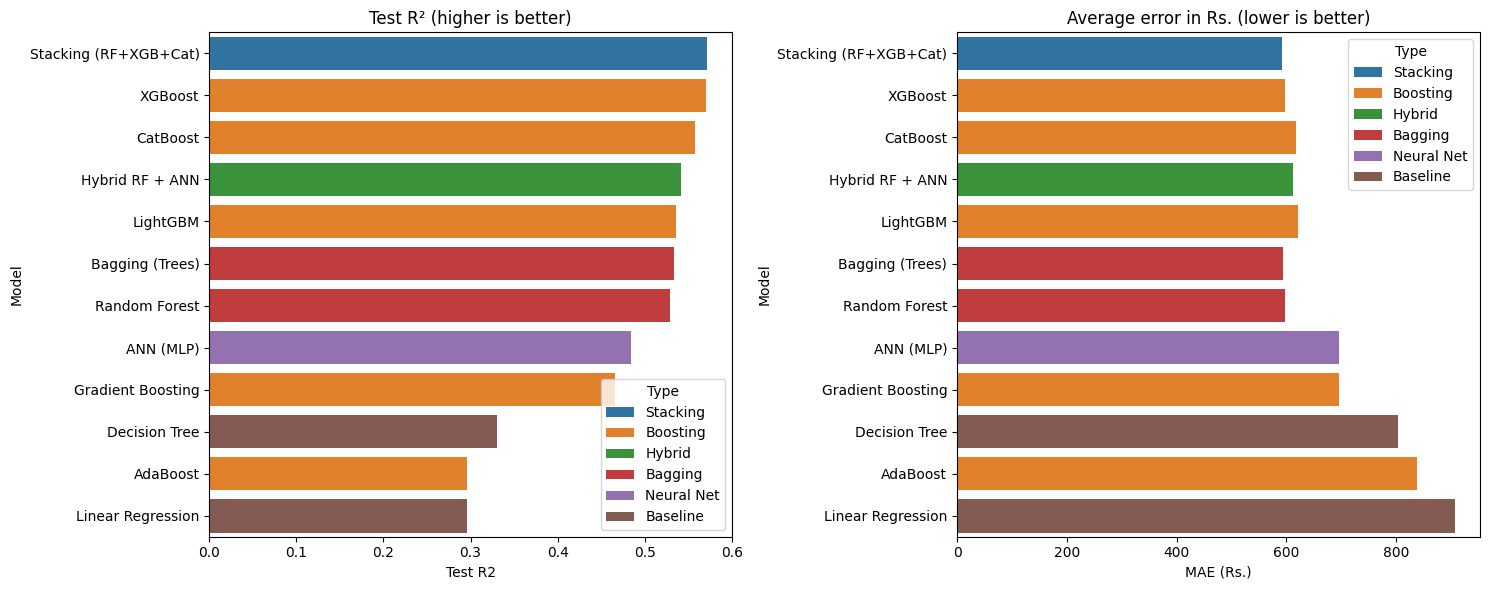

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=results_df, x="Test R2", y="Model", hue="Type", dodge=False, ax=axes[0])
sns.barplot(data=results_df, x="MAE (Rs.)", y="Model", hue="Type", dodge=False, ax=axes[1])
axes[0].set_title("Test R² (higher is better)")
axes[1].set_title("Average error in Rs. (lower is better)")
plt.tight_layout()
plt.show()

According to the above table and plots, the best models are Stacking (Test R squared 0.572, MAE = Rs.593) and XGBoost (Test R squared 0.570, MAE = Rs.597). And XGBoost has the highest CV R squared (0.584) which is more reliable than one test split. 

Ensemble clearly performed better than the baselines (Decision tree: 0.33, Linear regression: 0.3). Here, Decision tree shows overfitting with Train R squared of 0.93 which indicated a large gap. And ensembles have smaller gap so that they generalise better.  

Boosting performed best overall (XGBoost) with bagging close behind (Bagging 0.534, Random Forest 0.529). AdaBoost (0.296) is the weakest and it is not better than the baseline.

When considering speed, XGBoost trained in about 1s, while stacking took about 13s for almost no gain (0.572 vs 0.570). Therefore, XGBoost is the best choice.  

R squared is only about 0.57 because of the lack of key information (exact size, quality), as stated in previous notebook there are 418 products with unknown brands, for variable products it is considered the cheapest option to reduce the complexity and the dataset (1352 products) is small (3 other shops were excluded. Two shops do not allow their data to be used for AI training and one blocked automated access).

### 12. Feature Importance (Random Forest)

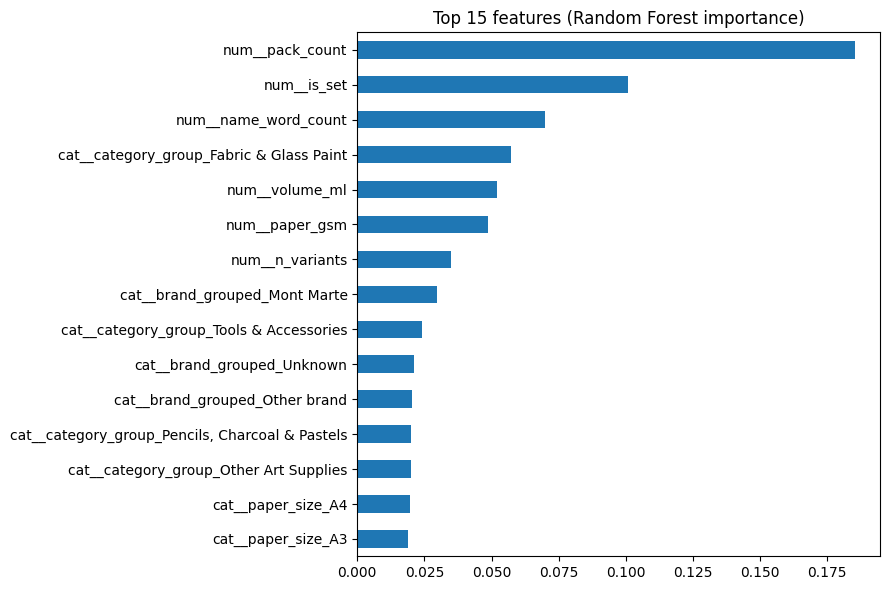

In [15]:
feature_names = rf.named_steps["prep"].get_feature_names_out()
importance = pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
importance.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 15 features (Random Forest importance)")
plt.tight_layout()
plt.show()

The most important features are pack_count and is_set followed by name_word_count, the Fabric & Glass Paint category, volume_ml and paper_gsm. This agrees with the EDA in previous notebook. Sets and bigger packs have higher prices and fabric paints are the cheapest.

### SHAP (Random Forest)

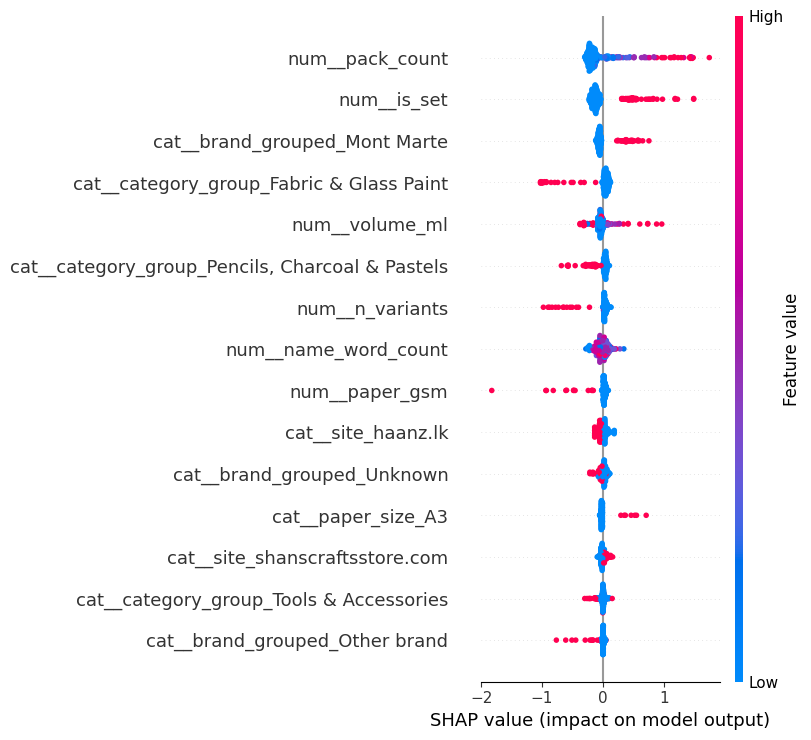

In [16]:
import shap

X_test_prep = rf.named_steps["prep"].transform(X_test)
if hasattr(X_test_prep, "toarray"):
    X_test_prep = X_test_prep.toarray()
X_test_prep = pd.DataFrame(X_test_prep, columns=rf.named_steps["prep"].get_feature_names_out())

explainer = shap.TreeExplainer(rf.named_steps["model"])
shap_values = explainer.shap_values(X_test_prep)
shap.summary_plot(shap_values, X_test_prep, max_display=15)

Here, each dot is a product. Red means a high feature value and blue means a low feature value.  
Dots on the right increase the predicted price. For example, red dots of pack_count, is_set and Mont Marte products are on the right, so sets, Mont Marte products and bigger packs increase the price. Paper sheets with gsm and Fabric & Glass paints have lower price which matches with EDA and feature importance.

### 13. RF vs Gradient Boosting

Random Forest builds trees independently and averages them. It is robust, hard to overfit, needs little tuning and is fast. But it can be less accurate.  
Gradient boosting (XGBoost, LightGBM, CatBoost) builds trees one after another to fix errors. It is often more accurate on tabular data but needs more tuning and can overfit.  XGBoost is fast and regularised and LightGBM is very fast on large data. 

CatBoost handles categories well and was close behind (0.558). According to my results, gradient boosting (XGBoost) beat Random Forest (0.570 and 0.529) which matches the idea that boosting is often more accurate on tabular data.  
Therefore, XGBoost can be considered as the best model for this.  

Tree ensembles work best on structured data such as rows and columns of features and the ANN here was weaker than trees but for images/texts it may perform better which trees cannot do well.

### 14. Save the Model

In [17]:
import os
os.makedirs("../models", exist_ok=True)

all_models = {"Linear Regression": lr, "Decision Tree": dt, "Bagging (Trees)": bag,
              "Random Forest": rf, "AdaBoost": ada, "Gradient Boosting": gbm,
              "XGBoost": xgb, "LightGBM": lgbm, "CatBoost": cat,
              "Stacking (RF+XGB+Cat)": stack, "ANN (MLP)": ann}

best_name = (results_df[results_df["Model"].isin(all_models)].sort_values("CV R2", ascending=False).iloc[0]["Model"])
joblib.dump(all_models[best_name], "../models/best_model.pkl")
joblib.dump(rf, "../models/random_forest.pkl")
joblib.dump(xgb, "../models/xgboost.pkl")
results_df.to_csv("../models/model_results.csv", index=False)
print("Best model saved:", best_name)

Best model saved: XGBoost


The XGBoost is saved as best_model.pkl because it has the highest CV R² which is more reliable than one test split.

In [18]:
from sklearn.model_selection import cross_val_predict

price = df["price_lkr"].values
errors = {}
for name, model in [("Random Forest", rf), ("XGBoost", xgb)]:
    pred = np.expm1(cross_val_predict(model, X, y, cv=kfold))
    errors[name] = np.abs(pred - price) / price
    print(f"{name}: median error {np.median(errors[name]) * 100:.1f}%")

closer = (errors["Random Forest"] < errors["XGBoost"]).mean() * 100
print(f"Random Forest is closer on {closer:.0f}% of products, XGBoost on {100 - closer:.0f}%")

Random Forest: median error 27.2%
XGBoost: median error 27.7%
Random Forest is closer on 58% of products, XGBoost on 42%


### 15. Overall Summary

XGBoost is the best model for this with Test R squared 0.57, CV R squared 0.584, MAE = Rs.597. Stacking shows similar R squared (0.572) but its training was much slower.  

All ensembles clearly beat the baselines. Boosting performed slightly better than bagging, stacking added little and the RF + ANN hybrid improved slightly on Random Forest alone but did not beat XGBoost.  
The main price drivers are pack size, sets, volume, brand (Mont Marte) and category.   

Also Random Forest and XGBoost are almost tied. In 5 fold cross validation, Random Forest is more closer on individual products (median error 27.2% vs 27.7%) but XGBoost has fewer large errors and it has a higher CV R squared (0.584 vs 0.556) and a lower MAE.  

I chose XGBoost because avoiding large errors impacts more for a price estimate. In the dashboard, it shows both models' predictions.

**Limitations**:  
a small dataset from 3 shops, one snapshot in time, missing brand and size information as stated previously.  

**Future Work**:  
Collecting data from more shops, collecting prices over time (RF + ARIMA), better size/brand extraction and using text features from product names.